# 13 · A deep field in HST and DESI, and what WCC sees of it

A real 3' x 3' patch of the **GOODS-North field, 2' south of the Hubble Deep Field North**, in HST and in DESI, how a WCC exposure of it looks in the three Lazuli filters
**g, r and i**, and what is known about the individual galaxies: DESI spectra, redshifts, stellar masses and star formation rates.

The field is chosen for its data. HST has F435W (B), F606W (V) and F814W (I) here, the closest match to the WCC `zwo:g`, `zwo:r` and `zwo:i`: F435W from the original GOODS ACS survey
(the CANDELS mosaics have no blue ACS band) and F606W and F814W from CANDELS. The Legacy Surveys DR10 imaging covers it in g, r and z (the north has no i-band, so the DESI colour image uses z as red).
The field is inside the DESI spectroscopic footprint, so galaxies in it have DESI spectra. The patch and the WCC frame were chosen so that all three HST bands cover the patch and the frame contains several
galaxies with DESI spectra.

| Part | Content | Data |
|---|---|---|
| **1** | **The field**: a 3' x 3' view in HST and in DESI, with colour images built by hand | GOODS ACS F435W, CANDELS ACS F606W, F814W; Legacy Surveys DR10 g, r, z |
| **2** | **What WCC sees**: a 52" x 35" frame simulated in WCC g, r and i from the HST images, next to the real HST and DESI images | the same data |
| **3** | **The galaxies**: zooms on the galaxies of the frame that have DESI spectra, with their spectra, redshifts, masses, star formation rates and shapes | DESI DR1 spectra (SPARCL), 3D-HST v4.1, Legacy Surveys Tractor |

The code lives in `scripts/` (`hst_cutouts.py`, `galaxy_ancillary.py`, `legacysurvey_galaxy_mock.py`); this notebook calls it. The DESI spectra need the SPARCL client
(`pip install sparclclient`). The first run downloads data (about 2 GB of HST mosaic rows for the 3' view (the CANDELS GOODS-North mosaic is 41000 pixels wide), a 40 MB catalog, a few small cutouts and the
Tractor catalog; several minutes here, depending on the archive's speed, and Data Lab can be slow, in which case the Tractor catalog comes from the legacysurvey.org viewer instead). Everything is cached in `ls_cache/` afterwards.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
from astropy.nddata import Cutout2D
from astropy.coordinates import SkyCoord
from astropy.stats import sigma_clipped_stats
from astropy.visualization import make_lupton_rgb
from reproject import reproject_interp
from scipy.ndimage import gaussian_filter, median_filter

sys.path.insert(0, os.path.abspath("../scripts"))
import galaxy_ancillary as ga
import hst_cutouts as hc
import legacysurvey_galaxy_mock as lsm
from wcc_sim import ImageComponent, detector_frame, empty_catalog, simulate_field
from wcc_sim.starflux import REF_MAG, rate_for_ab

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
# noisy images compress far better as JPEG than PNG (keeps the saved notebook small)
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

## Setup

Two positions: the centre of the 3' x 3' view, and the centre of the 52" x 35" WCC frame inside it, about 80" to its north-west. The patch is about 2' south of the Hubble Deep Field North. It is one of the places where F435W,
F606W and F814W all cover a 3' x 3' view inside one ACS mosaic tile (the CANDELS footprint is patchy and the GOODS tiles are 4' wide), and the frame position is the one of those that holds the most galaxies with DESI spectra.

In [2]:
FIELD = "goods-n"
RA, DEC = 189.2283, 62.17933             # the centre of the 3' view
FRA, FDEC = 189.19273, 62.19544          # the centre of the WCC frame
SENSORFILTER = "zwo:r"                   # the detector geometry; all three filters share it
SHAPE = (2048, 3072)                     # WCC subarray (ny, nx): 51.8" x 34.5"
CACHE = "ls_cache"

frame = detector_frame(SENSORFILTER, (FRA, FDEC), shape=SHAPE)
ny, nx = frame.shape
pix = frame.plate_scale_mas / 1000.0
width, height = nx * pix, ny * pix
half_diag = 0.5 * np.hypot(nx, ny) * pix
east_off, north_off = (FRA - RA) * np.cos(np.radians(DEC)) * 3600, (FDEC - DEC) * 3600       # frame centre relative to the view centre
print(f"frame {nx} x {ny} px = {width:.1f}\" x {height:.1f}\" at {frame.plate_scale_mas:.2f} mas/px; {east_off:.0f}\" east and {north_off:.0f}\" north of the view centre")

def regrid(data, wcs, out_wcs, shape):
    """Bilinear reprojection of an image onto another WCS (NaN outside the image)."""
    out, _ = reproject_interp((data, wcs), out_wcs, shape_out=shape, order="bilinear")
    return out

def nanomaggies(data, zp, pixel):
    return data * 10.0 ** (0.4 * (22.5 - zp)) / pixel**2         # an AB flux density per arcsec^2

frame 3072 x 2048 px = 51.8" x 34.5" at 16.87 mas/px; -60" east and 58" north of the view centre


In [3]:
# colour-stretch settings (the white point, in noise-sigmas of the summed intensity; see Part 1)
STRETCH_HST, STRETCH_DESI = 6.0, 15.0
STRETCH_WCC_HST = 8.0

# Part 1 · The field: a 3' x 3' view of GOODS-North in HST and DESI

The same 3' x 3' field in two surveys:

* **HST**: F435W from the original GOODS ACS survey (about 7200 s) and F606W and F814W from CANDELS, all at 30 mas/pixel. Sharp and deep, over a small part of the sky.
* **DESI Legacy Surveys DR10**: g and r from the Bok telescope (BASS) and z from the Mayall telescope (MzLS), at about 1" seeing, over much of the northern sky. There is no i-band here.

Every band is converted to nanomaggies per arcsec^2 (an AB flux density; the HST pixel values are in e-/s and use the zero points of the GOODS documentation for F435W and of the CANDELS headers for F606W and F814W) and put on
one north-up 60 mas pixel grid (the ACS bands are binned 2 x 2).

In [4]:
FOV = 180.0                                      # arcsec: 3' x 3'

def bin_wcs(wcs, n):
    """WCS of an image binned n x n."""
    out = wcs.deepcopy()
    out.wcs.crpix = (wcs.wcs.crpix - 0.5) / n + 0.5
    if wcs.wcs.has_cd():
        out.wcs.cd = wcs.wcs.cd * n
    else:
        out.wcs.cdelt = wcs.wcs.cdelt * n
    return out

t0 = time.perf_counter()
hst_cut = {"f435w": hc.fetch_goods_cutout(RA, DEC, FOV, FOV, "f435w", field=FIELD, cache_dir=CACHE)}       # (data, wcs, zero point, header), 30 mas
hst_cut.update({band: hc.fetch_candels_cutout(RA, DEC, FOV, FOV, band, field=FIELD, cache_dir=CACHE,
                                                max_download_mb=2000) for band in ("f606w", "f814w")})
print(f"HST cutouts {hst_cut['f606w'][0].shape} in {time.perf_counter() - t0:.0f} s (cached reads are instant)")

grid_wcs = bin_wcs(hst_cut["f606w"][1], 2)                       # the 60 mas north-up grid of every band below
grid_shape = (hst_cut["f606w"][0].shape[0] // 2, hst_cut["f606w"][0].shape[1] // 2)
bin2 = lambda a: a[:grid_shape[0] * 2, :grid_shape[1] * 2].reshape(grid_shape[0], 2, grid_shape[1], 2).mean(axis=(1, 3))
hst_bands = {band: bin2(nanomaggies(data, zp, 0.030)) for band, (data, wcs, zp, _) in hst_cut.items() if band != "f435w"}   # the CANDELS bands share a grid
d435, w435, zp435, _ = hst_cut["f435w"]                          # the GOODS F435W mosaic is on a different 30 mas grid: bin it, then put it on the common one
n435 = (d435.shape[0] // 2 * 2, d435.shape[1] // 2 * 2)
b435 = nanomaggies(d435[:n435[0], :n435[1]], zp435, 0.030).reshape(n435[0] // 2, 2, n435[1] // 2, 2).mean(axis=(1, 3))
hst_bands["f435w"] = regrid(b435, bin_wcs(w435, 2), grid_wcs, grid_shape)

t0 = time.perf_counter()
desi_bands = {}
for band in "grz":
    data, wcs = lsm.fetch_ls_cutout(RA, DEC, FOV, layer="ls-dr10", band=band, npix=700)        # 0.26"/px
    desi_bands[band] = regrid(data / (FOV / 700) ** 2, wcs, grid_wcs, grid_shape)
print(f"DESI g, r, z cutouts in {time.perf_counter() - t0:.0f} s")
print("data in the whole grid:", {k: f"{np.mean(np.isfinite(v) & (v != 0)):.0%}" for k, v in {**hst_bands, **desi_bands}.items()})

HST cutouts (6000, 6000) in 0 s (cached reads are instant)


DESI g, r, z cutouts in 10 s
data in the whole grid: {'f606w': '100%', 'f814w': '100%', 'f435w': '100%', 'g': '100%', 'r': '100%', 'z': '100%'}


## Making a colour image yourself

A colour image is three single-band images assigned to red, green and blue, with one common brightness stretch so that the *colours* are kept. The recipe uses the Lupton et al.
(2004) asinh stretch, `astropy.visualization.make_lupton_rgb`, as in the PHANGS notebook, with two additions that make a deep field of faint galaxies look right:

1. **Subtract the sky** of each band (its median).
2. **Balance the colours.** Equal weights in AB flux density do not give natural colours, because the sky and most galaxies are not equally bright in all bands. The bands are
   therefore scaled so that the median *detected* pixel is neutral grey; bluer than typical objects then show blue and redder ones red, as in the Hubble Deep Field.
3. **Set the stretch from the noise, not from the brightest pixels.** The PHANGS notebook puts the white point at the 99.5th percentile of one band, which suits big bright
   galaxies; in a field of faint compact ones the bright stars would then set the scale and the galaxies vanish. Here the white point is `stretch_sigma` times the noise of the
   summed intensity, and the black level (`minimum`) is one noise-sigma, so sky noise stays black.
4. `make_lupton_rgb(R, G, B, Q, stretch, minimum)` stretches the *summed intensity* with an asinh curve (linear for faint pixels, logarithmic for bright ones) and scales the three
   channels by the same factor, so a pixel's colour ratios survive the stretch. `Q` sets how soft the transition is.

The wavelength order sets the colours: the longest band goes to red, the shortest to blue (HST: F814W, F606W, F435W; DESI: z, r, g; the DESI z band is redder than the HST F814W).

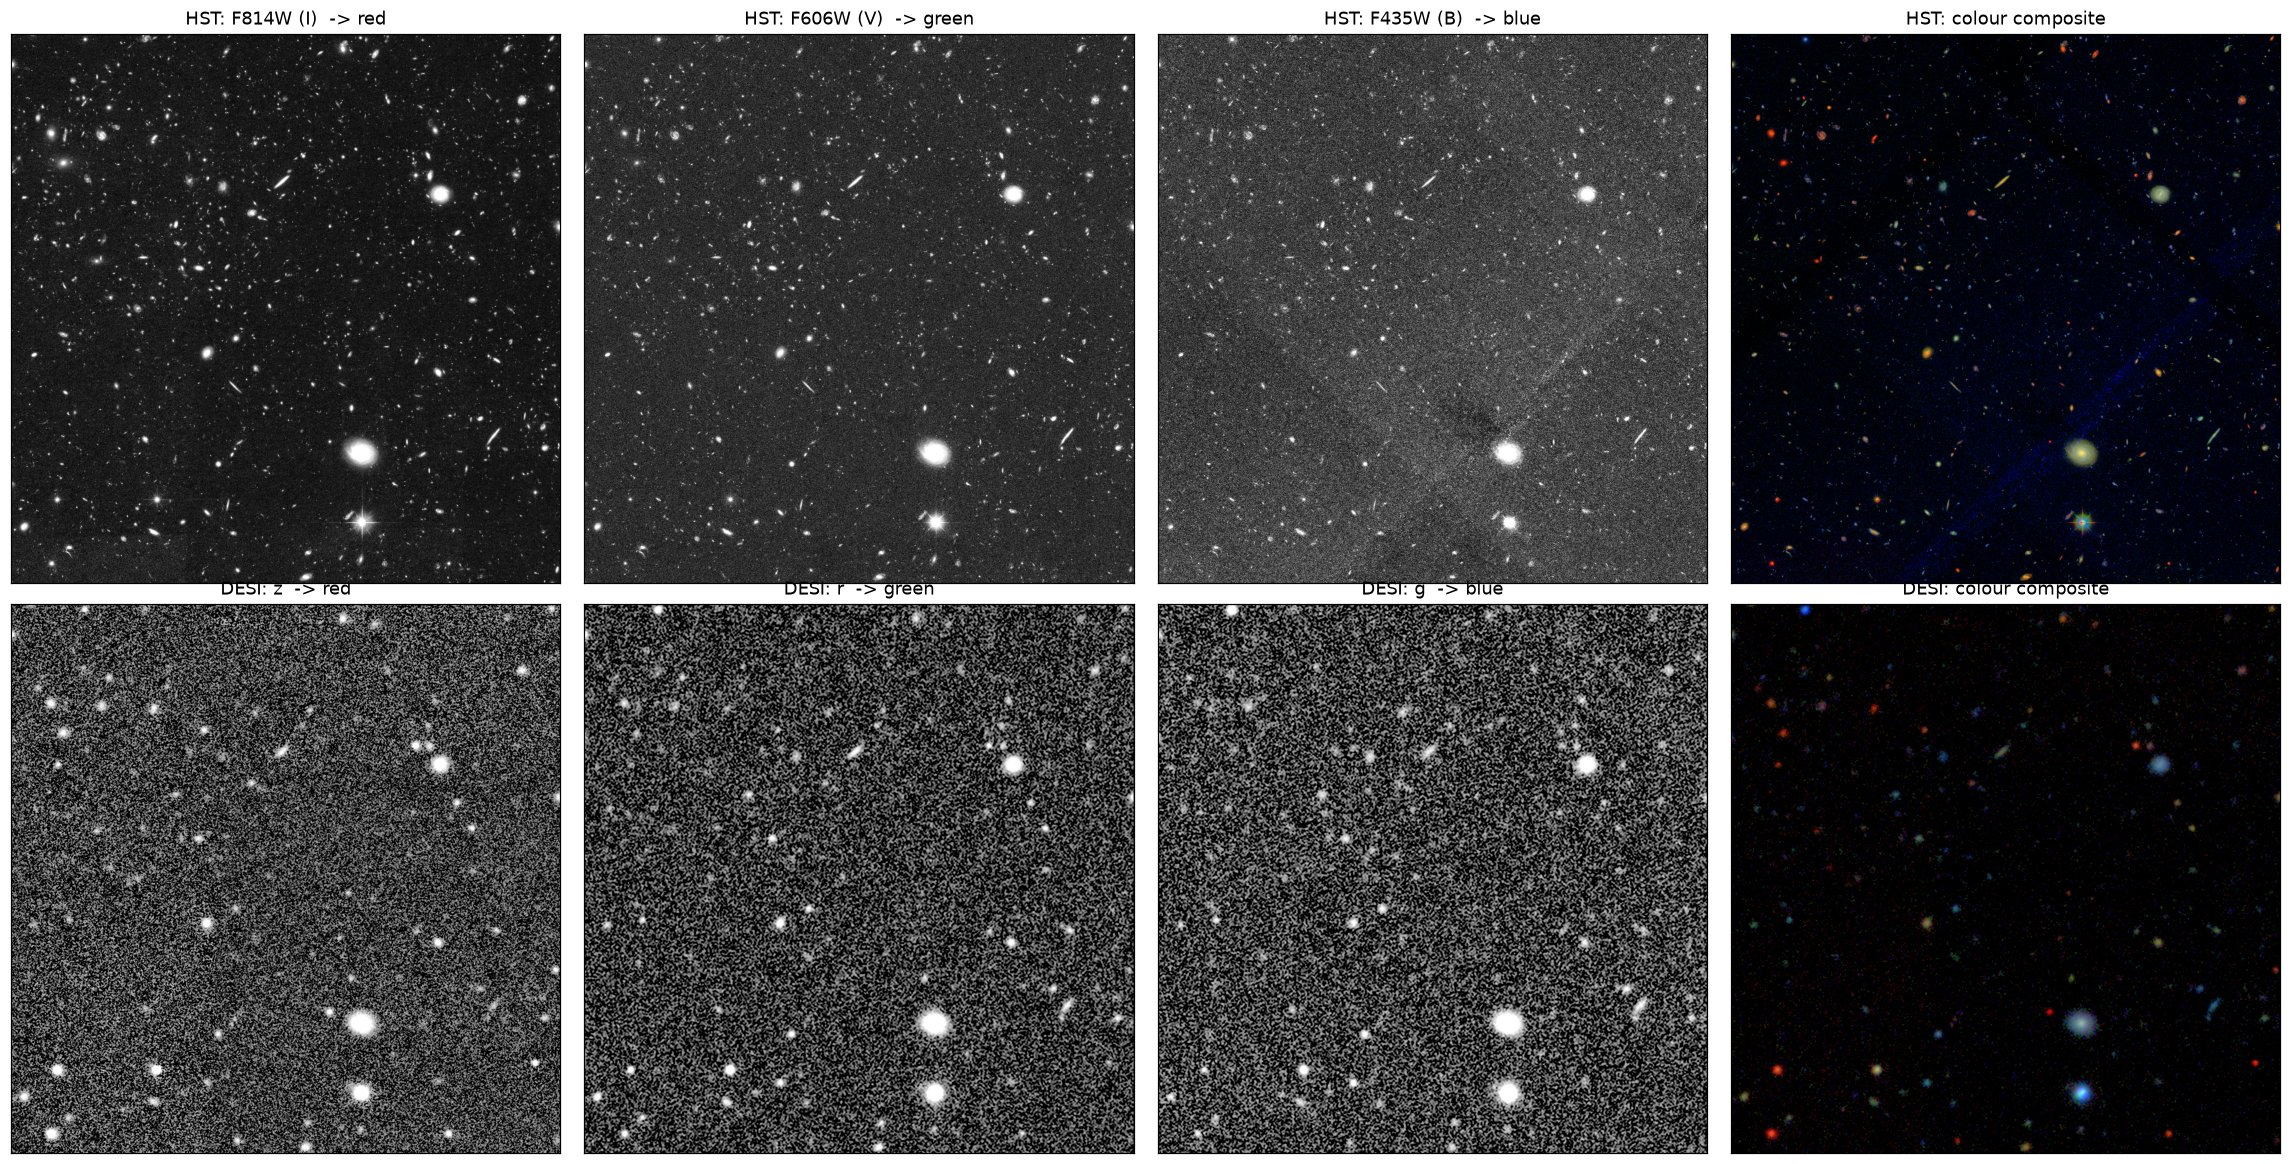

In [5]:
def colour_image(red, green, blue, stretch_sigma=8.0, Q=10.0, floor_sigma=1.0, detect_sigma=5.0):
    chans = [np.nan_to_num(a - np.nanmedian(a)) for a in (red, green, blue)]               # 1. sky-subtract
    noise = [sigma_clipped_stats(c, sigma=3)[2] for c in chans]
    detected = sum(c / s for c, s in zip(chans, noise)) > detect_sigma * np.sqrt(3)        # 2. colour balance: the median detected pixel
    flux = [np.median(c[detected]) for c in chans]                                         #    becomes neutral, with the middle band as the reference
    chans = [c * flux[1] / f for c, f in zip(chans, flux)]
    sigma_I = sigma_clipped_stats(sum(chans) / 3, sigma=3)[2]                              # noise of the summed intensity
    return make_lupton_rgb(*chans, Q=Q, stretch=stretch_sigma * sigma_I,                   # 3. + 4. noise-based white point, asinh stretch
                           minimum=floor_sigma * sigma_I)

def own_stretch(img, soft=20.0, hi_pct=99.7):
    good = np.isfinite(img)
    med, sig = sigma_clipped_stats(img[good], sigma=3)[1:]
    lo, hi = med - 0.5 * sig, np.nanpercentile(img[good], hi_pct)
    return np.clip(np.arcsinh((np.nan_to_num(img, nan=lo) - lo) / (hi - lo) * soft) / np.arcsinh(soft), 0, 1)

hst_rgb = colour_image(hst_bands["f814w"], hst_bands["f606w"], hst_bands["f435w"], stretch_sigma=STRETCH_HST)
desi_rgb = colour_image(desi_bands["z"], desi_bands["r"], desi_bands["g"], stretch_sigma=STRETCH_DESI)      # DESI's colours are noisier: a gentler stretch

# the ingredients of each composite (each band on its own stretch), then the result
half = FOV / 2
fig, axes = plt.subplots(2, 4, figsize=(21, 10.6))
rows = (("HST", (hst_bands["f814w"], "F814W (I)  -> red"), (hst_bands["f606w"], "F606W (V)  -> green"), (hst_bands["f435w"], "F435W (B)  -> blue"), hst_rgb),
        ("DESI", (desi_bands["z"], "z  -> red"), (desi_bands["r"], "r  -> green"), (desi_bands["g"], "g  -> blue"), desi_rgb))
for row, (name, *bands, rgb) in zip(axes, rows):
    for ax, (img, label) in zip(row[:3], bands):
        ax.imshow(own_stretch(img), origin="lower", cmap="gray", vmin=0, vmax=1, extent=(-half, half, -half, half))
        ax.set_title(f"{name}: {label}")
    row[3].imshow(rgb, origin="lower", extent=(-half, half, -half, half))
    row[3].set_title(f"{name}: colour composite")
    for ax in row:
        ax.invert_xaxis(); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

### The two colour images, with the WCC frame

Both on the same grid and field of view. The dashed rectangle is the 52" x 35" WCC frame that Part 2 simulates.

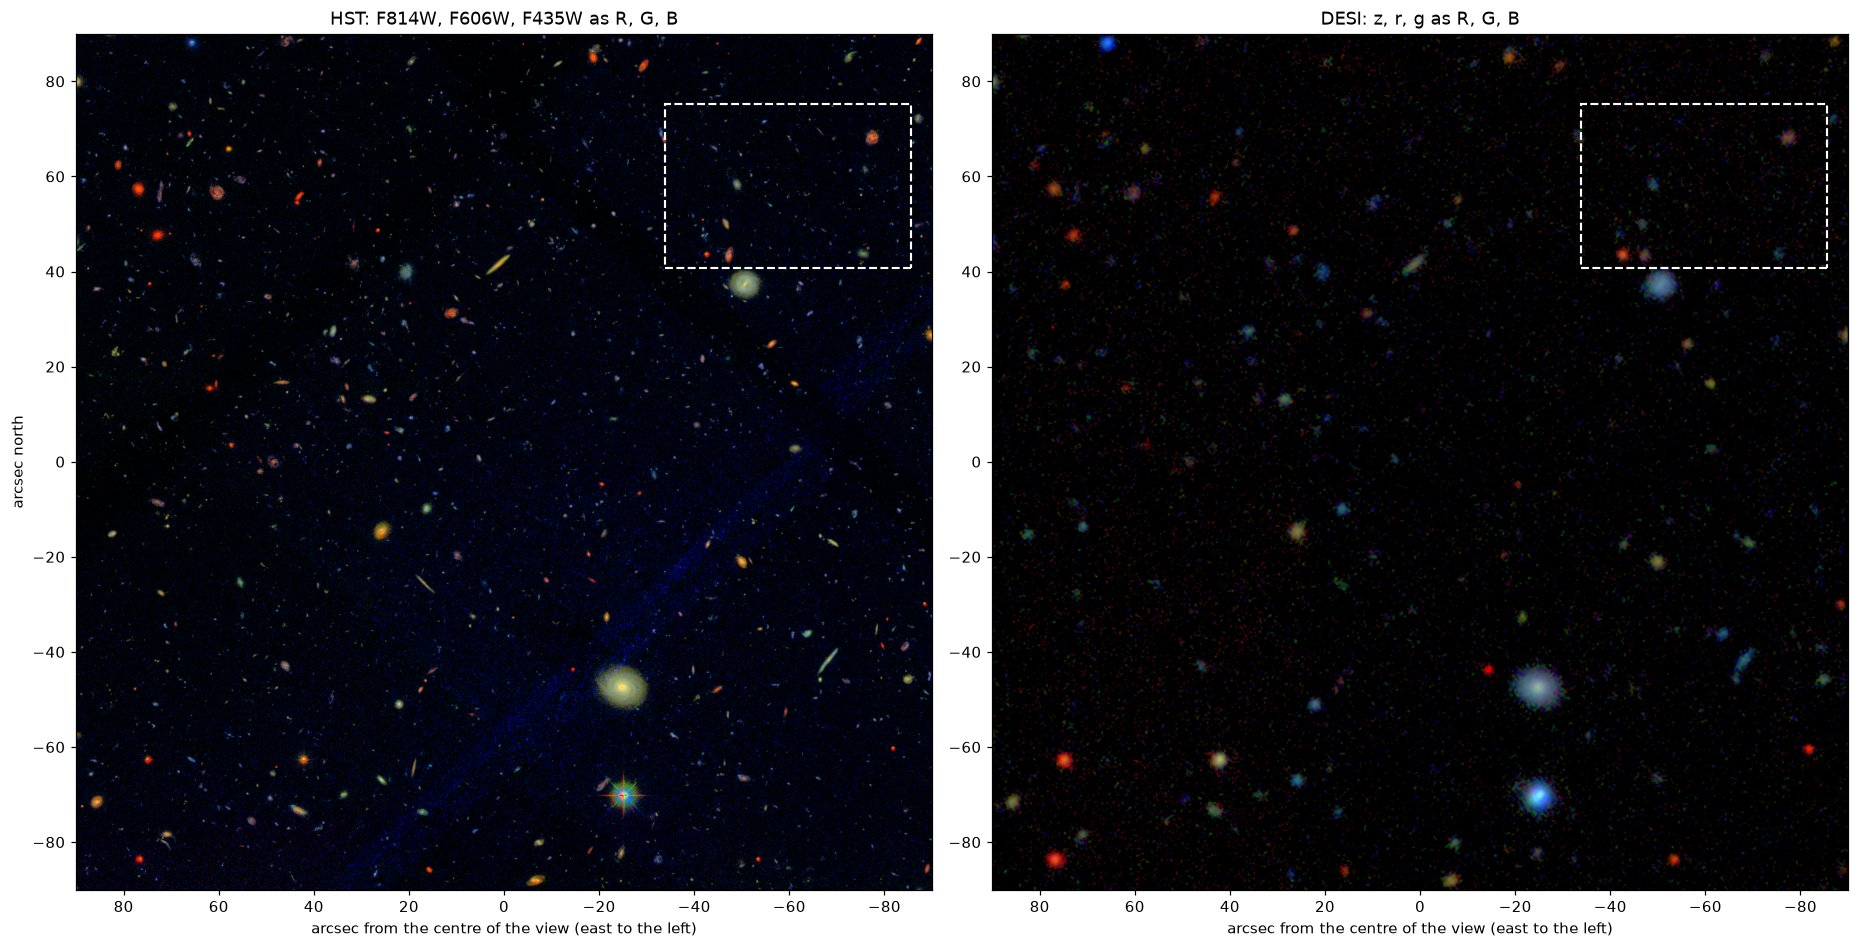

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8.4))
for ax, (rgb, title) in zip(axes, ((hst_rgb, "HST: F814W, F606W, F435W as R, G, B"), (desi_rgb, "DESI: z, r, g as R, G, B"))):
    ax.imshow(rgb, origin="lower", extent=(-half, half, -half, half))
    ax.add_patch(Rectangle((east_off - width / 2, north_off - height / 2), width, height, fill=False, ec="w", lw=1.4, ls="--"))
    ax.set_title(title); ax.set_xlabel("arcsec from the centre of the view (east to the left)"); ax.invert_xaxis()
axes[0].set_ylabel("arcsec north")
fig.tight_layout()

# Part 2 · What WCC sees: a g-r-i colour image, from the HST images

The 52" x 35" frame, simulated with the WCC `zwo:g`, `zwo:r` and `zwo:i` filters from the HST images: F435W goes in as `zwo:g`, F606W as `zwo:r` and F814W as
`zwo:i` (the closest HST bands; each image is taken to be in the WCC band it is simulated in).

Each filter is one simulation with the typical GOODS-North F606W exposure (about 1.6 h; the mosaics have no exposure map) as a stack of equal frames, and the three are coloured with the recipe of Part 1.
The image itself goes into the simulation (`ImageComponent`), so the WCC image is the input image seen through the WCC PSF, pixels and noise: WCC cannot add detail that is not in the image that goes in.

In [7]:
N_FRAMES = 6                             # equal frames in the stack
T_EXP = hc.GOODS_TYPICAL_EXPOSURE_S[FIELD]["f606w"]                  # the GOODS V-band exposure of a typical region (the mosaics have no exposure map)
BANDS = (("f435w", "g"), ("f606w", "r"), ("f814w", "i"))          # HST band and the WCC filter it is simulated as
print(f"exposure {T_EXP:.0f} s = {T_EXP / 3600:.2f} h -> a stack of {N_FRAMES} x {T_EXP / N_FRAMES:.0f} s in each filter")

# the 52" x 35" frame is cut out of the 3' HST images of Part 1 (same pixels, no second download); DESI cutouts are fetched at their own pixel size
hst_crop = {hb: Cutout2D(hst_cut[hb][0], SkyCoord(FRA, FDEC, unit="deg"), (round(height / 0.030), round(width / 0.030)),
                         wcs=hst_cut[hb][1], mode="strict") for hb, _ in BANDS}
desi_crop = {db: lsm.fetch_ls_cutout(FRA, FDEC, 256 * 0.262, layer="ls-dr10", band=db, npix=256) for db in "grz"}      # for the DESI panel only

# the real images on the WCC pixel grid
hst_frame = {db: regrid(nanomaggies(hst_crop[hb].data, hst_cut[hb][2], 0.030), hst_crop[hb].wcs, frame.wcs, frame.shape) for hb, db in BANDS}
desi_frame = {db: regrid(desi_crop[db][0] / 0.262**2, desi_crop[db][1], frame.wcs, frame.shape) for db in "grz"}

exposure 5650 s = 1.57 h -> a stack of 6 x 942 s in each filter


## Simulate WCC in g, r and i

One call per filter: `exptime` is the total, `n_reads` the number of frames, so the simulator applies Poisson noise on source, sky and dark, read noise once per frame, and saturation
per frame. Gaia is switched off because the stars are already in the images. `ImageComponent` clips negative pixels to zero, which would turn the positive half of the image noise into frozen sky
signal, so only connected regions of detected light are kept (`mask_to_sources`).

In [8]:
def observe(component, sensorfilter, seed):
    f = simulate_field(FRA, FDEC, sensorfilter=sensorfilter, exptime=T_EXP, n_reads=N_FRAMES, shape=SHAPE, seed=seed,
                       extended_sources=[component], catalog=empty_catalog())
    nmgy = 10.0 ** (0.4 * (22.5 - REF_MAG)) * (f.image_e / T_EXP) / rate_for_ab(REF_MAG, sensorfilter)
    sb = nmgy / pix**2
    return sb - np.nanmedian(sb)

wcc_hst = {}
for k, (hb, db) in enumerate(BANDS):
    wcc_hst[db] = observe(ImageComponent(hc.mask_to_sources(hst_crop[hb].data), hst_crop[hb].wcs, hst_cut[hb][2]), f"zwo:{db}", 1 + k)
print("simulated:", ", ".join(f"WCC {db} from HST" for _, db in BANDS))

simulated: WCC g from HST, WCC r from HST, WCC i from HST


## The colour images of the frame

Three colour images of the frame: the real HST and DESI images and the WCC mock. The WCC image is smoothed lightly for display (sigma = 2 WCC pixels = 34 mas, below the ~50 mas WCC PSF)
because the noise of a single frame of the stack at the native 17 mas pixel would otherwise show as coloured speckle.

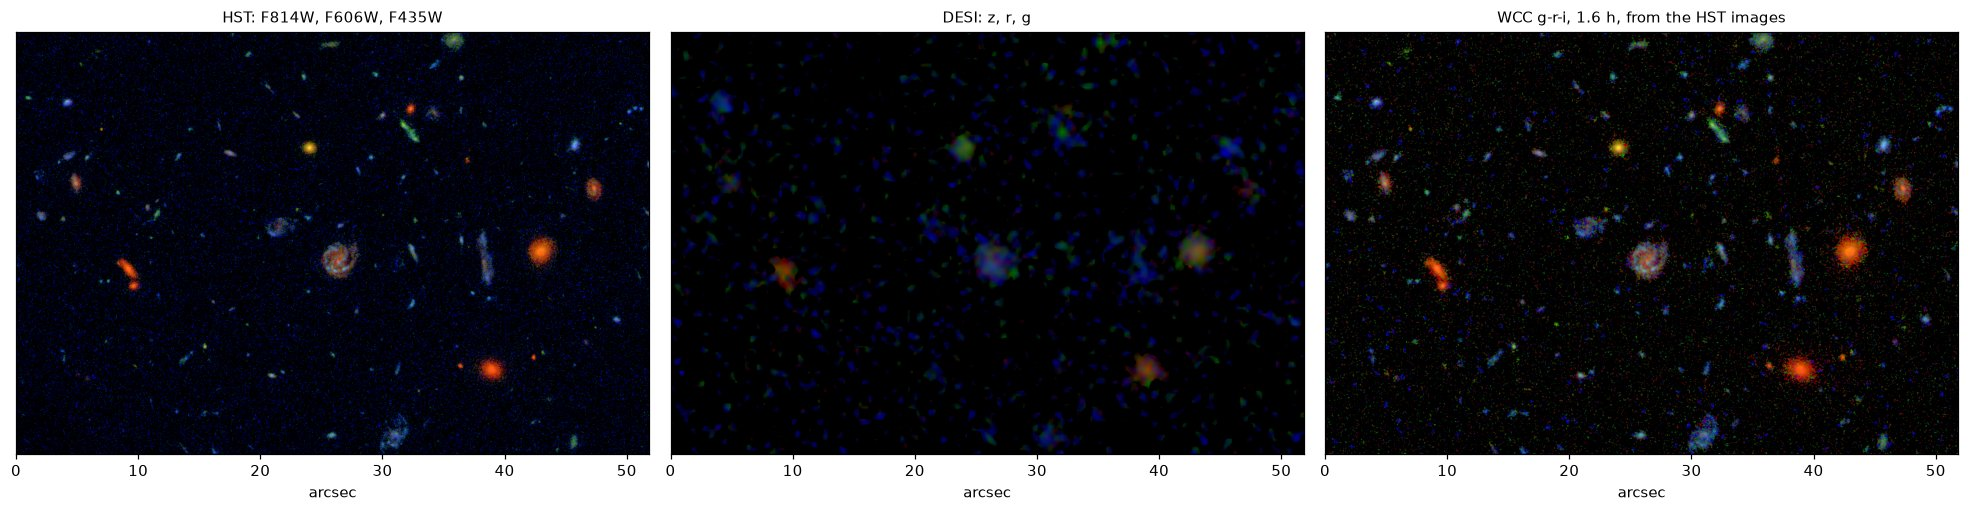

In [9]:
hst_frame_rgb = colour_image(hst_frame["i"], hst_frame["r"], hst_frame["g"], stretch_sigma=STRETCH_HST)
desi_frame_rgb = colour_image(desi_frame["z"], desi_frame["r"], desi_frame["g"], stretch_sigma=STRETCH_DESI)
smooth = lambda bands: {b: gaussian_filter(np.nan_to_num(a), 2.0) for b, a in bands.items()}
wcc_hst_rgb = colour_image(*(smooth(wcc_hst)[b] for b in "irg"), stretch_sigma=STRETCH_WCC_HST)

T_LABEL = f"{T_EXP / 3600:.1f} h"
PANELS = [(hst_frame_rgb, "HST: F814W, F606W, F435W"), (desi_frame_rgb, "DESI: z, r, g"),
          (wcc_hst_rgb, f"WCC g-r-i, {T_LABEL}, from the HST images")]

fig, axes = plt.subplots(1, 3, figsize=(18, 6.0 * height / width + 0.8))
for ax, (img, title) in zip(axes, PANELS):
    ax.imshow(img, origin="lower", extent=(0, width, 0, height))
    ax.set_title(title, fontsize=10); ax.set_yticks([]); ax.set_xlabel("arcsec")
fig.tight_layout()

# Part 3 · The galaxies: spectra, redshifts, masses and star formation rates

The galaxies of the frame that have a **DESI spectrum**, found with the NOIRLab SPARCL service (DESI DR1), and what else is known about them:

* **DESI**: the spectrum, the redshift and its error.
* **3D-HST v4.1** (Skelton et al. 2014): the stellar mass and star formation rate from SED fits (FAST) at the best redshift, and the photometric redshift as a cross-check. The star formation rate of a galaxy
  with no measurable star formation is a floor value in the catalog, shown here as "quiescent".
* **Legacy Surveys Tractor**: the fitted profile (exponential, de Vaucouleurs or Sersic), the Sersic index, the half-light radius and the axis ratio, measured on the DECam/BASS images at about 1" seeing. These are
  rough for galaxies a few arcseconds across; the "shape" column is a rule of thumb from them (n >= 2.5 spheroid-like, axis ratio < 0.4 elongated), not a visual classification.

In [10]:
t0 = time.perf_counter()
spec = ga.desi_galaxy_spectra(FRA, FDEC, half_diag)                                   # DESI galaxies in the frame's circumscribed circle
gx, gy = frame.wcs.world_to_pixel_values(spec["ra"], spec["dec"])
edge = 100                                                                           # px: keep each galaxy and its surroundings inside the frame
spec = spec[(gx > edge) & (gx < nx - edge) & (gy > edge) & (gy < ny - edge)]
print(f"{len(spec)} DESI galaxy spectra inside the frame ({time.perf_counter() - t0:.0f} s)")

cat3d = ga.fetch_3dhst(FIELD, cache_dir=CACHE)
k3d, _ = ga.match_catalog(spec["ra"], spec["dec"], cat3d, max_sep_arcsec=1.0)

tractor = lsm.fetch_tractor(FRA, FDEC, half_diag + lsm.QUERY_MARGIN_ARCSEC, release="ls_dr10", cache_dir=CACHE)
kt, _ = ga.match_catalog(spec["ra"], spec["dec"], tractor, max_sep_arcsec=1.5)

4 DESI galaxy spectra inside the frame (2 s)


In [11]:
def tractor_shape(row):
    """(profile, sersic n, half-light radius [arcsec], axis ratio b/a) from a Tractor row."""
    kind = str(row["type"]).strip()
    if kind == "PSF":                                    # unresolved at DECam's resolution: Tractor fits no shape
        return kind, np.nan, np.nan, np.nan
    e = float(np.hypot(row["shape_e1"], row["shape_e2"]))
    q = (1 - e) / (1 + e)
    n = {"EXP": 1.0, "REX": 1.0, "DEV": 4.0}.get(kind, float(row["sersic"]) if kind == "SER" else np.nan)
    return kind, n, float(row["shape_r"]), q

def shape_class(kind, n, q):
    if kind == "PSF":
        return "unresolved in DECam"
    if q < 0.4:
        return "elongated / edge-on disc-like"
    if kind == "REX":                                    # a round exponential with a fitted size but a fixed n = 1: no profile information
        return "compact, round (n not fitted)"
    return "spheroid-like" if n >= 2.5 else "disc-like"

records = []
for i in range(len(spec)):
    row = {"DESI z": spec["redshift"][i], "z error": spec["redshift_err"][i], "ra": spec["ra"][i], "dec": spec["dec"][i], "sparcl_id": spec["sparcl_id"][i]}
    if k3d[i] >= 0:
        c = cat3d[k3d[i]]
        row.update({"3D-HST z": c["z_spec"] if c["z_spec"] > 0 else c["z_peak"], "log M*": c["lmass"],
                    "SFR [Msun/yr]": 10.0 ** c["lsfr"] if c["lsfr"] > -90 else 0.0})
    if kt[i] >= 0:
        kind, n, r_eff, q = tractor_shape(tractor[kt[i]])
        row.update({"profile": kind, "n": n, "r_eff [arcsec]": r_eff, "b/a": q, "shape": shape_class(kind, n, q),
                    "AB r": 22.5 - 2.5 * np.log10(max(float(tractor["flux_r"][kt[i]]), 1e-9))})
    records.append(row)
galaxies = pd.DataFrame(records).sort_values("AB r").reset_index(drop=True)
galaxies = galaxies.head(5)
galaxies.index = np.arange(1, len(galaxies) + 1)
show = galaxies.drop(columns=["ra", "dec", "sparcl_id"])
show.style.format({"DESI z": "{:.4f}", "z error": "{:.1e}", "3D-HST z": "{:.3f}", "log M*": "{:.2f}", "SFR [Msun/yr]": "{:.2f}",
                   "n": "{:.1f}", "r_eff [arcsec]": "{:.2f}", "b/a": "{:.2f}", "AB r": "{:.1f}"}, na_rep="-")

,DESI z,z error,3D-HST z,log M*,SFR [Msun/yr],profile,n,r_eff [arcsec],b/a,shape,AB r
1,1.0118,1.3e-04,1.013,11.42,0.14,REX,1.0,0.53,1.00,"compact, round (n not fitted)",22.6
2,1.0131,1.0e-04,1.013,10.85,0.00,DEV,4.0,0.79,0.43,spheroid-like,22.7
3,0.9624,3.0e-05,0.963,9.28,2.19,PSF,-,-,-,unresolved in DECam,23.5
4,1.2391,6.1e-05,1.239,9.63,6.46,PSF,-,-,-,unresolved in DECam,23.6


## Zooms and spectra

One row per galaxy: the HST, DESI and WCC colour images, and the DESI spectrum (flux smoothed over 15 pixels in grey, the best-fit template in red) with the strongest lines at the DESI redshift marked.

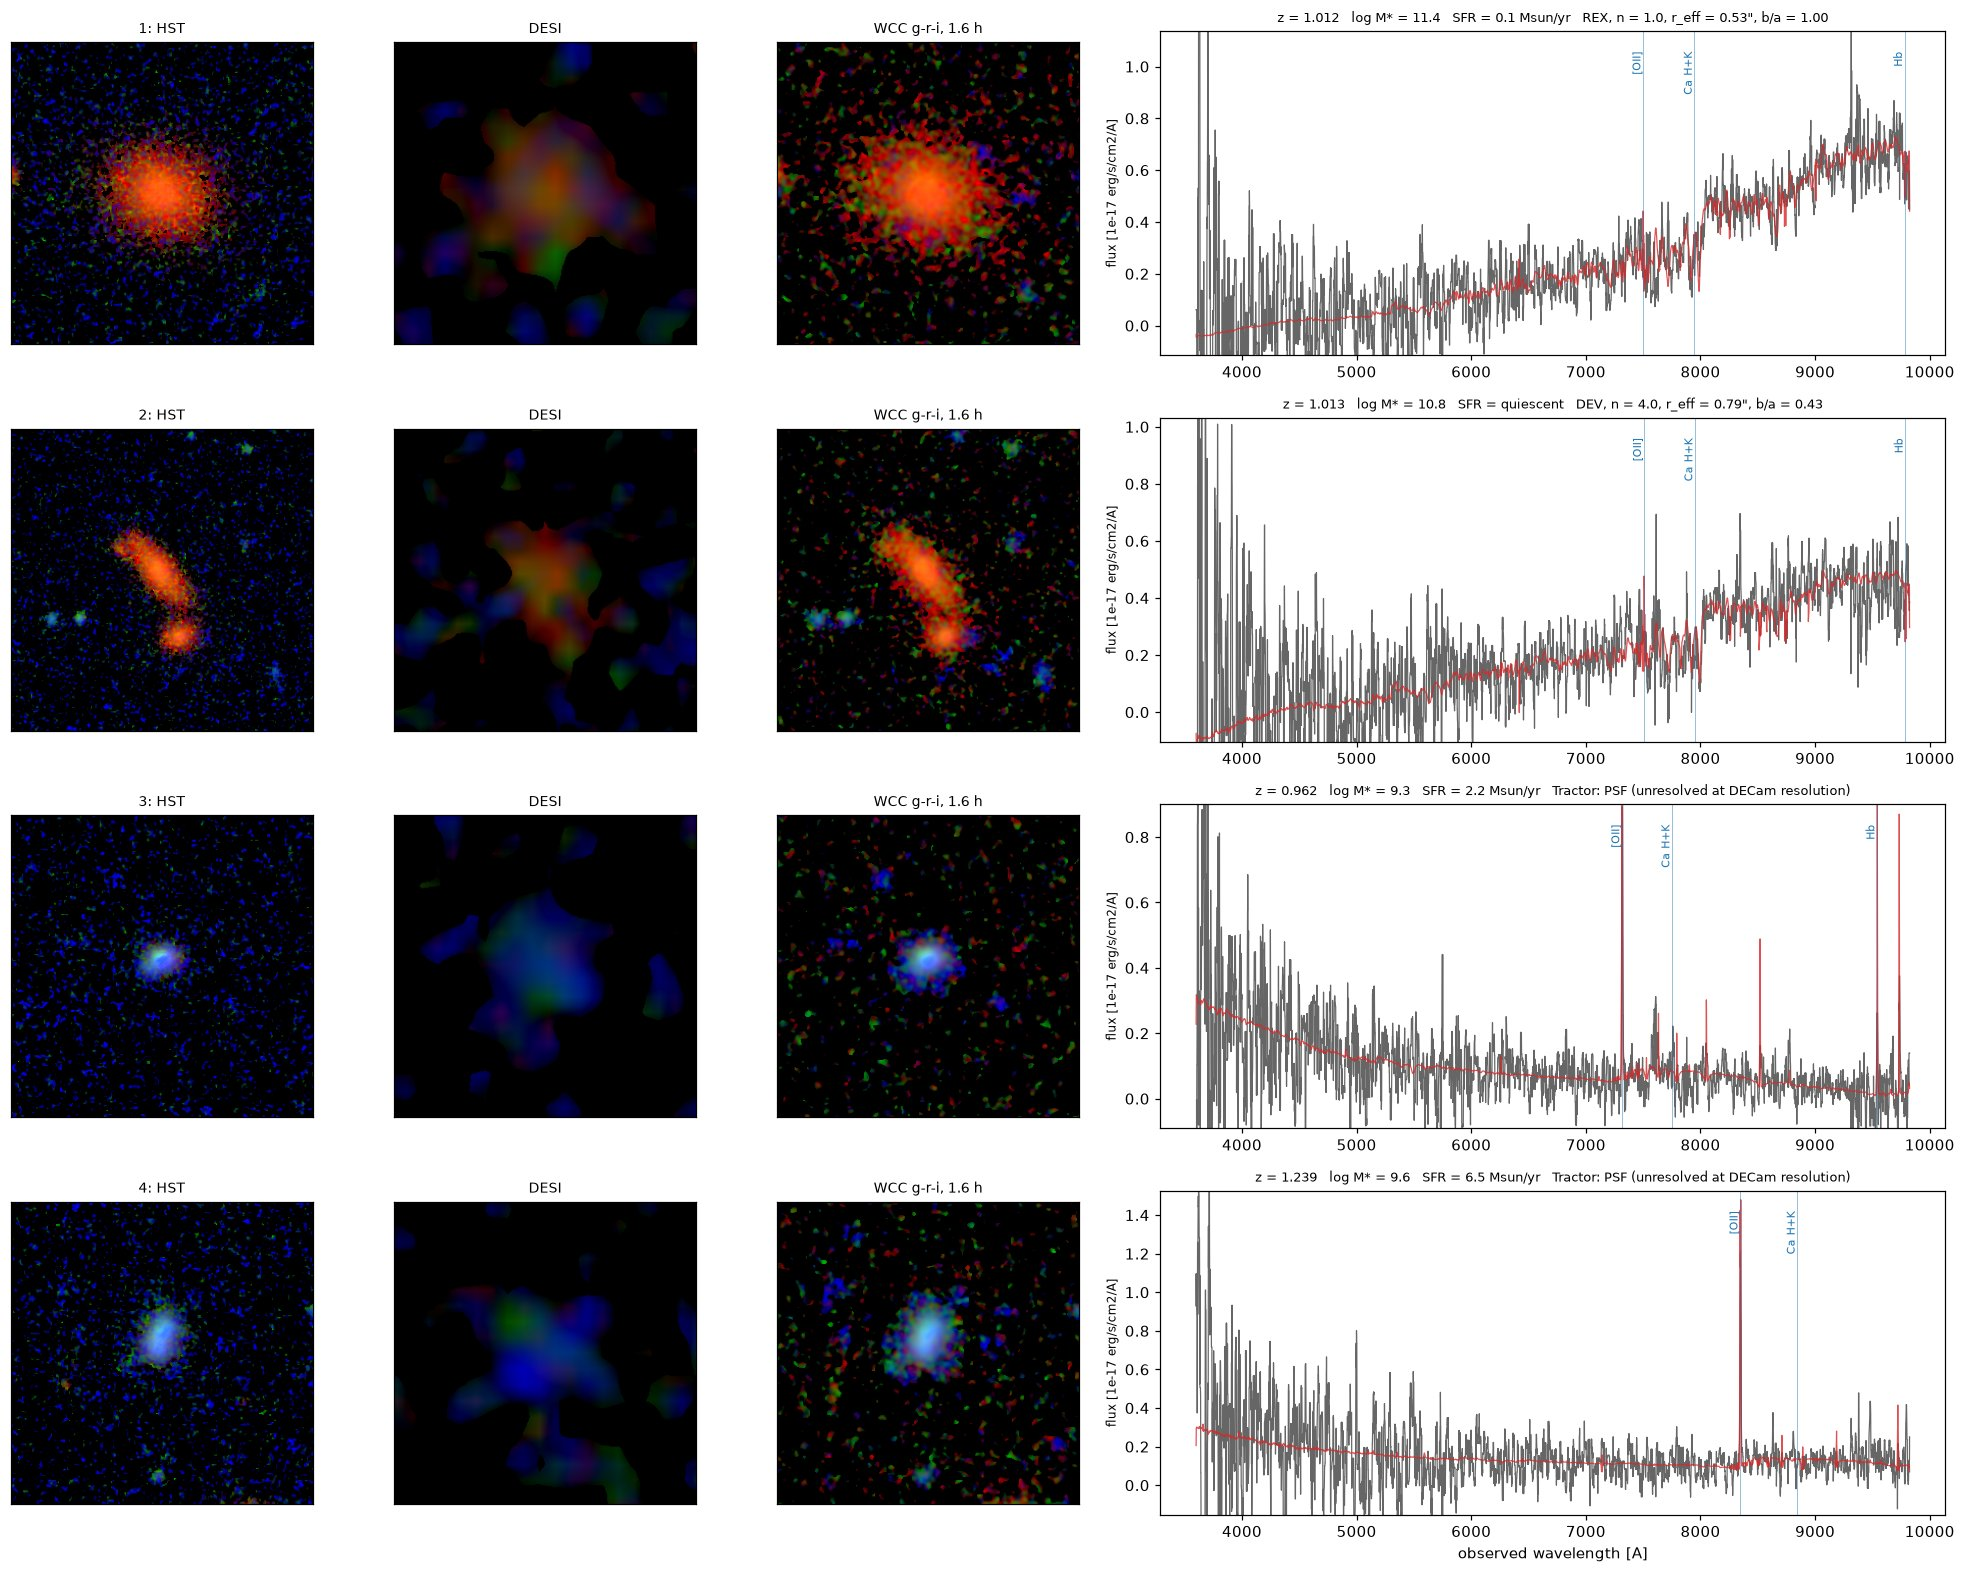

In [12]:
LINES = {"[OII]": 3727.3, "Ca H+K": 3950.0, "Hb": 4861.3, "[OIII]": 5006.8, "Mg b": 5175.0, "Na D": 5893.0, "Ha": 6562.8}
zoom_cols = ((hst_frame_rgb, "HST"), (desi_frame_rgb, "DESI"), (wcc_hst_rgb, f"WCC g-r-i, {T_LABEL}"))
fig = plt.figure(figsize=(18, 3.6 * len(galaxies)))
grid = GridSpec(len(galaxies), 4, width_ratios=[1, 1, 1, 2.6], figure=fig)
for r, (_, g) in enumerate(galaxies.iterrows()):
    gxp, gyp = frame.wcs.world_to_pixel_values(g["ra"], g["dec"])
    r_eff = g.get("r_eff [arcsec]", np.nan)
    h = int(np.clip(4 * (r_eff if np.isfinite(r_eff) else 0.6), 2.5, 8.0) / pix)
    cx, cy = int(gxp), int(gyp)
    sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
    for c, (img, title) in enumerate(zoom_cols):
        ax = fig.add_subplot(grid[r, c])
        ax.imshow(img[sl], origin="lower"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{r + 1}: {title}" if c == 0 else title, fontsize=9)
    ax = fig.add_subplot(grid[r, 3])
    wave, flux, ivar, model = ga.desi_spectrum(g["sparcl_id"])
    ok = ivar > 0
    ax.plot(wave[ok], median_filter(flux[ok], 15), color="0.4", lw=0.8)
    ax.plot(wave[ok], model[ok], color="tab:red", lw=0.8, alpha=0.8)
    top = np.nanpercentile(median_filter(flux[ok], 15), 99.5) * 1.3
    ax.set_ylim(-0.1 * top, top)
    for name, w0 in LINES.items():
        w = w0 * (1 + g["DESI z"])
        if wave[0] < w < wave[-1]:
            ax.axvline(w, color="tab:blue", lw=0.6, alpha=0.5); ax.text(w, top * 0.93, name, rotation=90, ha="right", va="top", fontsize=7, color="tab:blue")
    ax.set_ylabel("flux [1e-17 erg/s/cm2/A]", fontsize=8)
    sfr = g.get("SFR [Msun/yr]", np.nan)
    ax.set_title(f"z = {g['DESI z']:.3f}   log M* = {g.get('log M*', np.nan):.1f}   SFR = " + ("quiescent" if sfr == 0 else f"{sfr:.1f} Msun/yr")
                 + "   " + (f"{g['profile']}, n = {g['n']:.1f}, r_eff = {r_eff:.2f}\", b/a = {g['b/a']:.2f}" if np.isfinite(r_eff)
                              else "Tractor: PSF (unresolved at DECam resolution)"), fontsize=8.5)
    if r == len(galaxies) - 1:
        ax.set_xlabel("observed wavelength [A]")
fig.tight_layout()